In [3]:
import gdsfactory as gf
import numpy as np
from gdsfactory.typings import LayerSpec
from layers import LayerMap
import uuid

gf.gpdk.PDK.activate()

# ==============================================================================
# 2. Matrix Generation
# ==============================================================================
def generate_design_matrix(rows: int, cols: int) -> np.ndarray:
    return np.random.randint(0, 2, size=(rows, cols))

# ==============================================================================
# 3. Drawing Function
# ==============================================================================
def draw_pixelated_device(
    design_matrix: np.ndarray,
    layer_top: LayerSpec,
    layer_ground: LayerSpec,
    layer_top_port: LayerSpec,
    layer_ground_port: LayerSpec,
    pitch_x: float = 0.5,
    pitch_y: float = 0.5,
    pixel_w: float = 0.6,
    pixel_h: float = 0.6,
    tl_w: float = 2.0,
    tl_l: float = 10.0,
    port_stick_len: float = 1.0, 
) -> gf.Component:
    
    unique_name = f"pixelated_device_{uuid.uuid4().hex[:8]}"
    c = gf.Component(unique_name)
    
    rows, cols = design_matrix.shape
    
    # --- Geometry Calculations ---
    grid_width_centers = (cols - 1) * pitch_x
    x0 = -grid_width_centers / 2
    y0 = -(rows - 1) * pitch_y / 2

    # --- Draw Pixels ---
    pixel_rect = gf.components.rectangle(size=(pixel_w, pixel_h), layer=layer_top, centered=True)
    for r in range(rows):
        for col in range(cols):
            if design_matrix[r, col] == 1:
                ref = c << pixel_rect
                ref.move((x0 + (col * pitch_x), y0 + (r * pitch_y)))

    # --- Draw Transmission Lines ---
    tl_rect = gf.components.rectangle(size=(tl_l, tl_w), layer=layer_top, centered=True)
    
    tl1 = c << tl_rect
    tl1.movey(0)
    tl1.xmax = x0 - (pitch_x / 2)
    
    tl2 = c << tl_rect
    tl2.movey(0)
    tl2.xmin = x0 + (cols - 1) * pitch_x + (pitch_x / 2)

    # --- Draw Ground Plane ---
    margin = 2.0
    total_device_width = (tl2.xmax - tl1.xmin)
    total_device_height = max(((rows - 1) * pitch_y + pixel_h), tl_w)

    c << gf.components.rectangle(
        size=(total_device_width + 2*margin, total_device_height + 2*margin), 
        layer=layer_ground, 
        centered=True
    )

    # ==========================================================================
    # 4. ADD PORTS
    # ==========================================================================
    marker_shape_top = gf.components.rectangle(
        size=(port_stick_len, tl_w), 
        centered=True,
        layer=layer_top_port, 
    )

    marker_shape_gnd = gf.components.rectangle(
        size=(port_stick_len, tl_w), 
        centered=True,
        layer=layer_ground_port, 
    )

    # --- LEFT SIDE (Input) ---
    # Port 1: Top Signal
    p1 = c << marker_shape_top
    p1.xmin = tl1.xmin  # Flush Left
    p1.y = 0            
    
    # Port 2: Ground Reference
    p2 = c << marker_shape_gnd
    p2.xmin = tl1.xmin  # Flush Left
    p2.y = 0

    # --- RIGHT SIDE (Output) ---
    # Port 3: Top Signal
    p3 = c << marker_shape_top
    p3.xmax = tl2.xmax  # Flush Right
    p3.y = 0

    # Port 4: Ground Reference
    p4 = c << marker_shape_gnd
    p4.xmax = tl2.xmax  # Flush Right
    p4.y = 0

    # ==========================================================================
    # 5. RESTORE LABELS
    # ==========================================================================
    # We use tl1.xmin and tl2.xmax to place text exactly at the port edges.
    
    # Left Labels
    c.add_label(text="P1", position=(tl1.xmin, 0), layer=layer_top)
    c.add_label(text="P1_G", position=(tl1.xmin, 0), layer=layer_ground) 

    # Right Labels
    c.add_label(text="P2", position=(tl2.xmax, 0), layer=layer_top)
    c.add_label(text="P2_G", position=(tl2.xmax, -0), layer=layer_ground)

    c.flatten()
    # c2.name = unique_name # Ensure the flattened copy keeps the unique name
    
    return c, unique_name
# ==============================================================================
# Execution
# ==============================================================================

# 1. Instantiate your layer map
layermap = LayerMap

# 2. Generate the design matrix independently
my_matrix = generate_design_matrix(rows=20, cols=30)

# 3. Pass the matrix and the specific layers into the drawing function
device, name = draw_pixelated_device(
    design_matrix=my_matrix,
    layer_top=layermap.LB,
    layer_ground=layermap.JA,
    layer_top_port=layermap.LB_PIN,
    layer_ground_port=layermap.JA_PIN,
    tl_w=2.0 # Thin transmission line
)
device.write_gds(f"{name}.gds")  # Write it to a GDS file. You can open it in klayout.

device.show()

from emx_runner import EMXSimInterface

# 1. Define where you want to save the results
output_folder = "./simulation_results_batch_1"

# 2. Instantiate the interface
runner = EMXSimInterface(destination_folder=output_folder)

# 3. Define your inputs
my_gds_list = [
    "{name}.gds",
    # "another_device.gds",
]

my_cell_names = [
    name,
    # "another_device_top",
]

# 4. Run Batch
s_files = runner.run_batch(my_gds_list, my_cell_names)

print("\n--- Batch Complete ---")
print("Generated S-parameter files:")
for f in s_files:
    print(f)

--- Starting Simulation for: pixelated_device_7da97bc1 ---2026-01-16 14:48:01.073 | WARNING  | kfactory.kcell:show:3958 - Could not connect to klive server



EMX version 2025.1.0 (3fc3470) starting on ogras-elab-zeus-ak-3539aeh at Fri Jan 16 14:48:01 2026
Command line for EMX version 2025.1.0:
-----------------
/cae/apps/data/cadence-2025/installs/EMX20251/tools.lnx86/emx/bin/64bit/emx
/disk/mcao53/RFIC_RL/{name}.gds pixelated_device_7da97bc1
/disk/smiao23/GF22/PDK_240627_121855_281/22FDX-PLUS/V1.0_2.3/Emagnetic/EMX/10M_2Mx_5Cx_1Jx_2Qx_LBthick/22fdsoi_10M_2Mx_5Cx_1Jx_2Qx_LBthick_nominal_detailed.encrypted.proc
-e 0.25 -t 0.25 -v 0.5 --3d=-* -p P000=P1 -p P001=P2 -p P002=P1_G -p P003=P2_G
--sweep 0 6e+10 --sweep-stepsize 5e+08 --verbose=3 --print-command-line
--log-time-level=0 --extended-warnings
--message-file=/disk/mcao53/RFIC_RL/simulation_results_batch_1/pixelated_device_7da97bc1_emx.log
-l 0 --quasistatic --dump-connectivity --parallel=0 --simultaneous-frequencies=0
--recommended-memory --key=EMXkey --format=touchstone2 -s
/disk/mcao53/RFIC_RL/simulation_results_batch_1/pixelated_device_7da97bc1.s%dp
-----------------
64 CPUs detected


EMX Error for pixelated_device_7da97bc1. Exit code: 1
Failed: pixelated_device_7da97bc1

--- Batch Complete ---
Generated S-parameter files:


Memory limit of 243.81 GB out of 251.81 GB
CPU supports SSE level 6
OpenBLAS detected Zen
ERROR: can't determine installation root.
       can't determine the location of the executable "cds_root"
       using working directory "/disk/mcao53/RFIC_RL"
       and $PATH value "/filespace/m/mcao53/miniforge3/envs/rfic/bin:/cae/apps/data/mentor-2023/aok_cal_2023.2_35.23/bin:/filespace/m/mcao53/miniforge3/envs/rfic/bin:/filespace/m/mcao53/miniforge3/condabin:/cae/apps/data/mentor-2023/aok_cal_2023.2_35.23/bin:/usr/local/bin:/usr/bin:/bin:/usr/bin/X11:/opt/bin:/opt/condor/bin:/opt/cae/bin:/opt/cae/scripts"
ERROR: can't determine installation root.
       can't determine the location of the executable "cds_root"
       using working directory "/disk/mcao53/RFIC_RL"
       and $PATH value "/filespace/m/mcao53/miniforge3/envs/rfic/bin:/cae/apps/data/mentor-2023/aok_cal_2023.2_35.23/bin:/filespace/m/mcao53/miniforge3/envs/rfic/bin:/filespace/m/mcao53/miniforge3/condabin:/cae/apps/data/mentor-2023

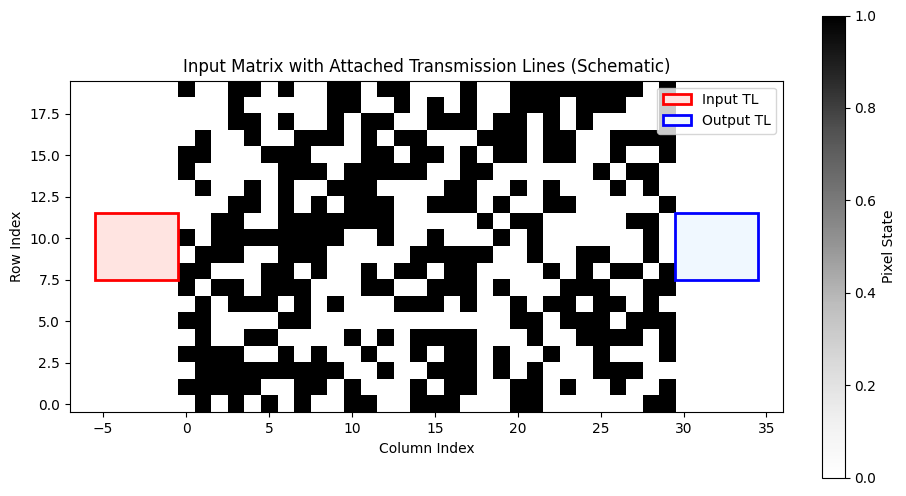

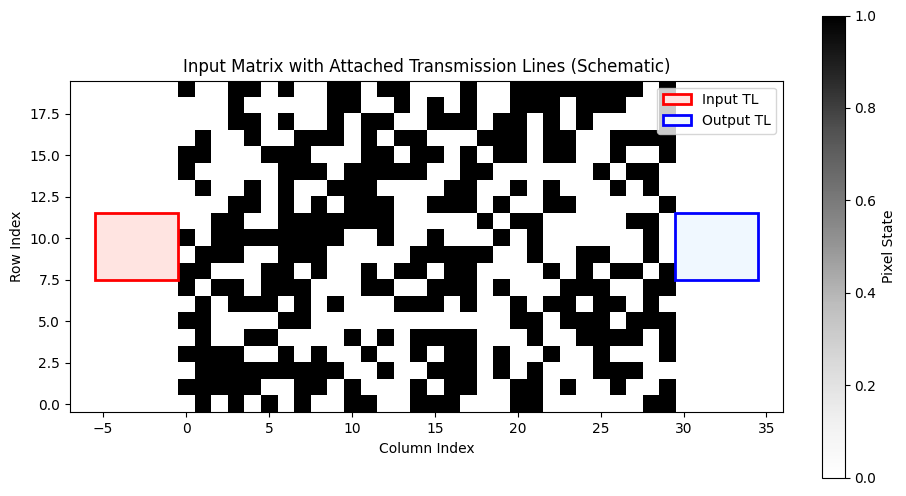

Physical GDS Layout:


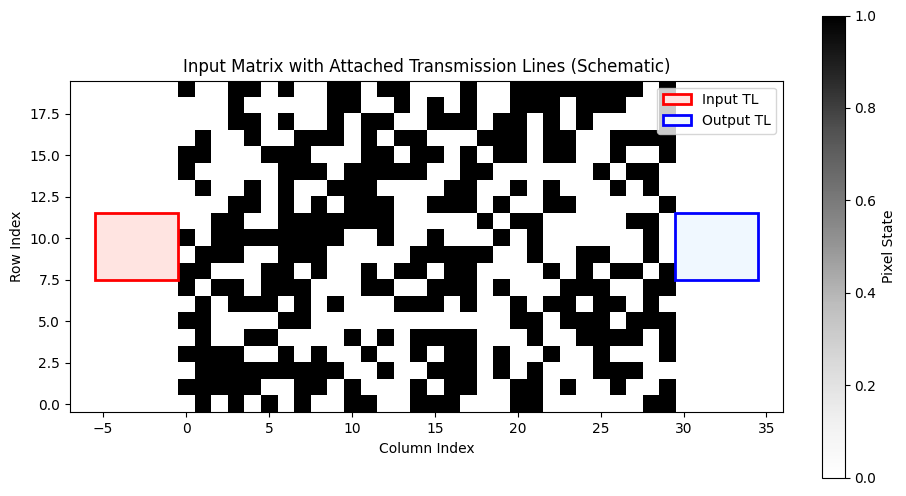

Physical GDS Layout:


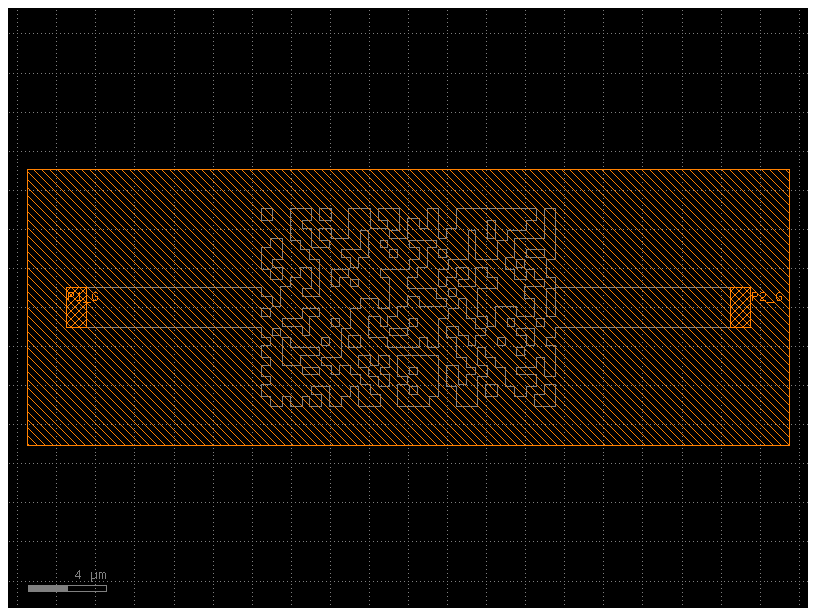

In [26]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches

# # 1. Visualize the Matrix with Schematic Transmission Lines
# # We overlay schematic rectangles to show where the TLs connect
# rows, cols = my_matrix.shape
# fig, ax = plt.subplots(figsize=(10, 6))

# # Plot the matrix data
# # origin='lower' ensures row 0 is at the bottom, matching the physical layout logic
# im = ax.imshow(my_matrix, cmap='Greys', interpolation='nearest', origin='lower')

# # Add schematic Transmission Lines (visual representation only)
# center_y_idx = (rows - 1) / 2.0
# schematic_tl_width_idx = 4.0   # Width in index units
# schematic_tl_len_idx = 5.0     # Length in index units

# # Left TL Stick
# rect_left = patches.Rectangle(
#     xy=(-0.5 - schematic_tl_len_idx, center_y_idx - schematic_tl_width_idx/2),
#     width=schematic_tl_len_idx, height=schematic_tl_width_idx,
#     linewidth=2, edgecolor='red', facecolor='mistyrose', label='Input TL'
# )
# ax.add_patch(rect_left)

# # Right TL Stick
# rect_right = patches.Rectangle(
#     xy=(cols - 0.5, center_y_idx - schematic_tl_width_idx/2),
#     width=schematic_tl_len_idx, height=schematic_tl_width_idx,
#     linewidth=2, edgecolor='blue', facecolor='aliceblue', label='Output TL'
# )
# ax.add_patch(rect_right)

# # Adjust plot limits to show the sticks
# ax.set_xlim(-schematic_tl_len_idx-2, cols + schematic_tl_len_idx + 1)
# ax.set_title("Input Matrix with Attached Transmission Lines (Schematic)")
# ax.set_xlabel("Column Index")
# ax.set_ylabel("Row Index")
# ax.legend(loc='upper right')
# plt.colorbar(im, label="Pixel State", fraction=0.03)
# plt.show()

# 2. Visualize the Physical GDS Component
# This renders the actual polygons using gdsfactory's matplotlib backend
print("Physical GDS Layout:")
device.plot() 

In [ ]:
# ==============================================================================
# 4. Interface to EMX Simulation
# ==============================================================================
import os
from emx_runner import EMXSimInterface

# 1. Save the generated GDS file
gds_filename = "pixelated_batch_01.gds"
gds_path = os.path.abspath(gds_filename)
device.write_gds(gds_path)
print(f"GDS saved to: {gds_path}")

# 2. Define your process file path (Update this path!)
proc_file_path = "/path/to/your/technology.proc"

# 3. Initialize the Runner
emx_runner = EMXSimInterface(proc_file=proc_file_path, work_dir="./emx_results")

# 4. Run Simulation (Examples for batch mode)
# In a real scenario, you might generate 100 designs in a loop and pass lists here.
results = emx_runner.run_batch(
    gds_batch=[gds_path], 
    cell_names=[device.name]
)

print("Simulation completed. S-parameter files:", results)

Frequency Points: 161


Frequency Points: 161


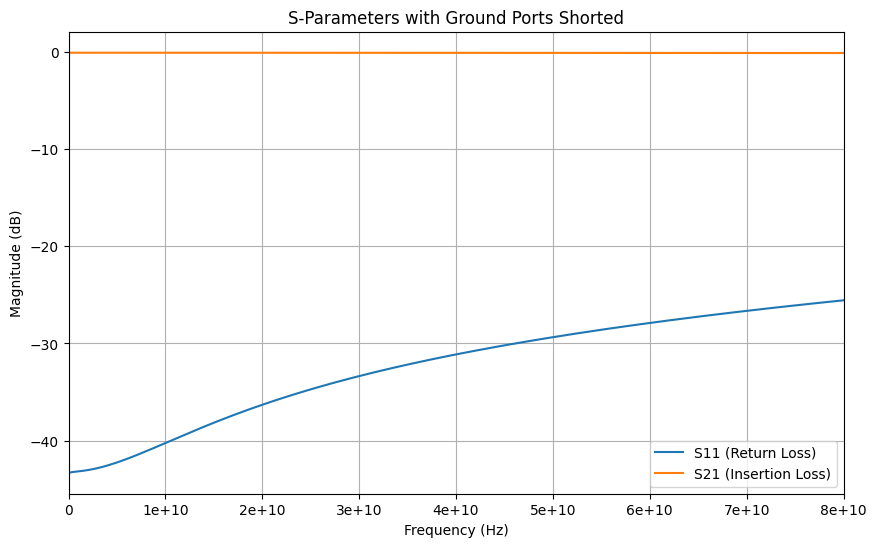

In [29]:
import skrf as rf
import matplotlib.pyplot as plt
import sys

sim_file_path = "/disk/mcao53/virtuoso/EMX_work/RFIntro_pixelated_device_ec5ebcb9.work/pixelated_device_ec5ebcb9.s4p"

net_4p = rf.Network(sim_file_path)

# Verify points (from your error, we know it is 41)
n_freqs = len(net_4p.frequency)
print(f"Frequency Points: {n_freqs}")

# ==============================================================================
# FIX: Create the Short Circuit with correct dimensions
# ==============================================================================
# We need an S-matrix of shape (N_freqs, 1, 1) filled with -1.0
s_short = np.full((n_freqs, 1, 1), -1.0 + 0j)

# We need a Z0 array of shape (N_freqs, 1) filled with 50.0
z0_short = np.full((n_freqs, 1), 50.0 + 0j)

# Create the explicit network
short = rf.Network(frequency=net_4p.frequency, s=s_short, z0=z0_short, name="short")

# ==============================================================================
# 2. Port Mapping (Assuming 'Signal First' order: P1, P2, G1, G2)
# ==============================================================================
# Double check your specific EMX output for these indices!
P1_SIG_IDX = 0
P2_SIG_IDX = 1
P1_GND_IDX = 2
P2_GND_IDX = 3

# ==============================================================================
# 3. Grounding Process
# ==============================================================================

# Step 1: Connect P1_GND to Short
step1 = rf.connect(net_4p, P1_GND_IDX, short, 0)

# Step 2: Connect P2_GND to Short
# Calculate new index for the remaining ground port
remaining_gnd_idx = P2_GND_IDX - 1 if P2_GND_IDX > P1_GND_IDX else P2_GND_IDX

net_2p = rf.connect(step1, remaining_gnd_idx, short, 0)
net_2p.name = "Renormalized_2Port"

# ==============================================================================
# 4. Plot Results
# ==============================================================================
plt.figure(figsize=(10, 6))
net_2p.plot_s_db(m=0, n=0, label='S11 (Return Loss)')
net_2p.plot_s_db(m=1, n=0, label='S21 (Insertion Loss)')
plt.grid(True)
plt.legend()
plt.title("S-Parameters with Ground Ports Shorted")
plt.show()

In [20]:
net_4p.port_names